# Lekcja 2. Pomiar i reguła Borna

**Cel:** zrozumieć, co dokładnie daje pomiar, czym jest kolaps i skąd biorą się histogramy z „shotów”.

## 1. Reguła Borna

Dla stanu $v = (\alpha, \beta)$ pomiar w bazie $\{e_0, e_1\}$ daje:

$$P(0) = |\alpha|^2 = |\langle e_0, v\rangle|^2, \qquad P(1) = |\beta|^2 = |\langle e_1, v\rangle|^2.$$

Reguła Borna przypisuje stanowi **rozkład prawdopodobieństwa wyników pomiaru**. Rozkład jest dwupunktowy (wyniki 0 i 1), może być zdegenerowany (np. dla $e_0$ jest $P(0) = 1$). Warunek $|\alpha|^2 + |\beta|^2 = 1$ to po prostu warunek, żeby prawdopodobieństwa sumowały się do jedynki.

> **To było trudne:** to jest rozkład **wyników**, a nie stanów. Stan znamy w całości, nie ma w nim nic losowego. Losowy jest tylko wynik.

## 2. Co naprawdę daje jeden pomiar

**Jeden wynik: 0 albo 1. Nic więcej.** Nie dwie liczby, nie wynik pośredni typu 0,49.

Dla stanu z $P(0) = 0{,}49$ i $P(1) = 0{,}51$:

- jeden pomiar daje 0 albo 1, losowo;
- **to nie jest argmax**: w 49% przypadków wyjdzie 0, mimo że $0{,}49 < 0{,}51$;
- żeby zobaczyć liczby 0,49 i 0,51, trzeba przygotować ten sam stan **wiele razy** i za każdym razem zmierzyć. To są **shoty**.

Prawdopodobieństwa można poznać na dwa sposoby:

- **teoria / symulator:** znamy stan, więc liczymy $|\alpha|^2$ dokładnie;
- **prawdziwy sprzęt:** stanu nie widać, więc **szacujemy** $|\alpha|^2$ z częstości wyników. Błąd standardowy szacunku to $\sqrt{p(1-p)/N} \le 0{,}5/\sqrt{N}$ dla $N$ shotów (przy 1000 shotów najwyżej ok. ±1,6 punktu procentowego).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # etykieta |0⟩
e1 = np.array([0, 1], dtype=complex)   # etykieta |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Wypisz wektor stanu z etykietami bitów (etykieta = pozycja w zapisie dwójkowym)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  pozycja {k} ({format(k, f'0{n}b')}): amplituda {np.round(a, 3)}, P = {abs(a)**2:.3f}")

rng = np.random.default_rng(7)
alpha, beta = np.sqrt(0.49), np.sqrt(0.51)
p0 = abs(alpha) ** 2

print("Pięć pojedynczych pomiarów:", rng.choice([0, 1], size=5, p=[p0, 1 - p0]))

for N in (10, 100, 1000, 100_000):
    wyniki = rng.choice([0, 1], size=N, p=[p0, 1 - p0])
    print(f"N = {N:>6}: oszacowanie P(0) = {np.mean(wyniki == 0):.3f}   (prawda: {p0:.2f})")

Pięć pojedynczych pomiarów: [1 1 1 0 0]
N =     10: oszacowanie P(0) = 0.600   (prawda: 0.49)
N =    100: oszacowanie P(0) = 0.460   (prawda: 0.49)
N =   1000: oszacowanie P(0) = 0.501   (prawda: 0.49)
N = 100000: oszacowanie P(0) = 0.489   (prawda: 0.49)

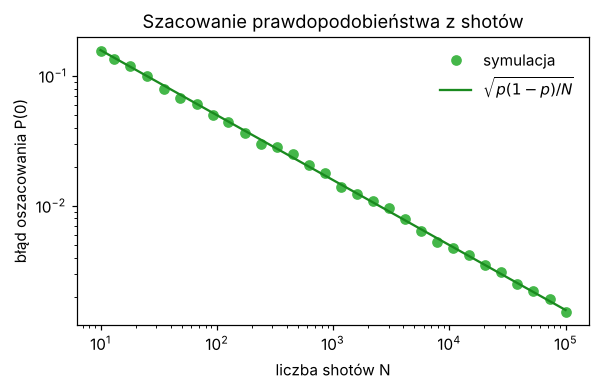

In [2]:
# Jak szybko maleje błąd oszacowania? Jak 1/sqrt(N).
Ns = np.unique(np.logspace(1, 5, 30).astype(int))
bledy = []
for N in Ns:
    proby = rng.binomial(N, p0, size=400) / N          # 400 powtórzeń eksperymentu po N shotów
    bledy.append(np.std(proby))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(Ns, bledy, "o", color=GREEN, label="symulacja")
ax.loglog(Ns, np.sqrt(p0 * (1 - p0) / Ns), color=DARK, label=r"$\sqrt{p(1-p)/N}$")
ax.set_xlabel("liczba shotów N"); ax.set_ylabel("błąd oszacowania P(0)")
ax.legend(frameon=False); ax.set_title("Szacowanie prawdopodobieństwa z shotów")

## 3. Kolaps

Kolaps mówi, co dzieje się ze **stanem po pomiarze**: jeśli wyszło 0, stan staje się $e_0$; jeśli 1, staje się $e_1$. Superpozycja znika, a z nią informacja o $\alpha$ i $\beta$.

Matematycznie to rzut i normalizacja. Rzut na $e_0$ to macierz $P_0 = e_0 e_0^{*} = \begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix}$, a nowy stan to

$$v \;\longmapsto\; \frac{P_0 v}{\|P_0 v\|} = \frac{(\alpha, 0)}{|\alpha|} \simeq e_0 \quad\text{(z dokładnością do fazy).}$$

Widać to eksperymentalnie: drugi pomiar wykonany zaraz po pierwszym daje **ten sam** wynik ze 100% pewnością.

In [3]:
def zmierz(v, rng):
    """Pomiar w bazie {e0, e1}: losuje wynik regułą Borna i zwraca (wynik, stan po kolapsie)."""
    p = np.abs(v) ** 2
    k = rng.choice(len(v), p=p)
    po = np.zeros_like(v); po[k] = v[k] / abs(v[k])      # rzut na e_k i normalizacja
    return k, po

v = np.array([np.sqrt(0.49), np.sqrt(0.51)], dtype=complex)
for proba in range(4):
    k1, po = zmierz(v, rng)
    k2, _ = zmierz(po, rng)
    print(f"pierwszy pomiar: {k1}, stan po nim: {np.round(po, 3)}, drugi pomiar: {k2}")

pierwszy pomiar: 0, stan po nim: [1.+0.j 0.+0.j], drugi pomiar: 0
pierwszy pomiar: 1, stan po nim: [0.+0.j 1.+0.j], drugi pomiar: 1
pierwszy pomiar: 1, stan po nim: [0.+0.j 1.+0.j], drugi pomiar: 1
pierwszy pomiar: 1, stan po nim: [0.+0.j 1.+0.j], drugi pomiar: 1

## 4. Pomiar to nie odczyt gotowej wartości

> **To było trudne:** naturalne jest myślenie „układ był w 0 albo w 1, a pomiar to sprawdził”. Tak nie jest.

- Przed pomiarem układ jest w stanie $(\alpha, \beta)$, a nie w 0 ani w 1.
- Pomiar **daje** wynik 0 albo 1, losowany z rozkładem $|\alpha|^2, |\beta|^2$.
- Pomiar **zmienia** stan na ten, który wyszedł.
- Samych $\alpha$ i $\beta$ odczytać się nie da.

Termometr pokazuje temperaturę, która była przed pomiarem. Pomiar kubitu tworzy wynik. Lekcja 3 pokazuje, że superpozycja to nie ukryte $e_0$ albo $e_1$ (stan $u_+$ kontra klasyczna moneta). To, że żaden model z ukrytymi wartościami nie działa, to treść twierdzenia Bella (lekcja 7).

**Fizycznie, w transmonie:** kubit jest sprzężony z rezonatorem mikrofalowym, którego częstotliwość przesuwa się minimalnie zależnie od stanu kubitu. Wysyła się słaby impuls sondujący i mierzy fazę odbitego sygnału; elektronika klasyfikuje go jako 0 albo 1. W ok. 1% przypadków klasyfikacja jest błędna (błąd odczytu, druga połowa SPAM).

**Czym kolaps jest „naprawdę”?** To otwarte pytanie fizyki (problem pomiaru). W standardowym ujęciu to postulat zgodny ze wszystkimi eksperymentami; dekoherencja wyjaśnia dużą część zjawiska, ale nie to, dlaczego wypada akurat ten wynik. Do programowania komputerów kwantowych wystarczą trzy reguły: wynik jest losowy, rozkład to $|\text{amplituda}|^2$, po pomiarze stan jest tym, co wyszło.

## Podsumowanie

> Mamy fizyczny układ dwupoziomowy. Jego stan opisujemy wektorem jednostkowym $(\alpha, \beta) \in \mathbb{C}^2$, który znamy z tego, jak układ przygotowaliśmy. Pomiar daje wynik 0 albo 1, losowany z rozkładem wyznaczonym przez stan: $P(0) = |\alpha|^2$, $P(1) = |\beta|^2$. Po pomiarze układ jest w stanie odpowiadającym wynikowi (kolaps). Model przewiduje **statystykę** wyników, a nie pojedynczy wynik, i to nie jest jego wada: w standardowej interpretacji mechaniki kwantowej pojedynczy wynik nie jest z góry ustalony.

Bramki (lekcja 5) zmieniają stan **deterministycznie**. Losowy jest wyłącznie pomiar.

## Zadania

1. Stan ma $P(0) = 0{,}49$ i $P(1) = 0{,}51$. Jeden pomiar dał 0. Jaki jest stan zaraz po pomiarze? Co da drugi pomiar?
2. 1000 shotów dało 487 zer i 513 jedynek. Jakie $|\alpha|^2$ i $|\beta|^2$ z tego szacujesz i z jakim błędem? Czy z tego da się odczytać znak $\beta$?
3. Wyniki z ibm_marrakesh dla obwodu Grovera (sekret 101): 783 trafienia na 1000 shotów. Jaki jest błąd statystyczny tej liczby? Czy może wyjaśnić różnicę względem 0,945 z symulatora?